# Topological charge: restart from the saved 40 K configuration
Restore the original Hamiltonian and final 40 K spins, then collect new samples with the corrected triangular plaquettes. Use a fresh kernel to load the updated Numba code. This is a new MC run with a new seed, not a continuation of the old RNG state.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import json
import secrets
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from nix2_mc import MonteCarloNiX2, KB_MEV_PER_K
from nix2_model_builders import build_nix2_lattice, build_nix2_model
from nix2_mc_protocols import run_mc_annealing
from nix2_mc_output import create_run_folder, load_scan_point
from plotting_3d_spins import PLOT_CONFIG, plot_spin_config, plot_curves
plt.rcParams.update(PLOT_CONFIG)


## 1. Load the saved 40 K configuration


In [2]:
source_folder = Path("nix2_simulation_results/NiX2_topological_charge__20261103_100708_163558")
source_parameters = json.loads((source_folder / "parameters.json").read_text(encoding="utf-8"))
initial_temperature_K = 40.0
matches = []
for path in sorted((source_folder / "data").glob("*.npz")):
    with np.load(path, allow_pickle=False) as data:
        if np.isclose(float(data["parameter__temperature_K"]), initial_temperature_K):
            matches.append(path)
source_file, = matches
initial_point = load_scan_point(source_file)
initial_spins = np.ascontiguousarray(initial_point["spins"], dtype=float)
Nmuc = int(initial_point["parameters"]["Nmuc"])
print(f"Loaded {source_file}: T = {initial_temperature_K:g} K, shape = {initial_spins.shape}, Nmuc = {Nmuc}")

Loaded nix2_simulation_results\NiX2_topological_charge__20261103_100708_163558\data\00020.npz: T = 40 K, shape = (48, 48, 1, 3), Nmuc = 6


## 2. Restore the Hamiltonian and initialize MC


In [3]:
geometry = source_parameters["geometry"]
model_params = dict(source_parameters["model_params"])
model_params["J1"] = np.asarray(model_params.pop("J1mat"))

nix2_lattice = build_nix2_lattice(source_parameters["Nx"], source_parameters["Ny"], geometry=geometry)
nix2_model = build_nix2_model(**model_params, geometry=geometry)

mc_seed = secrets.randbits(128)
nix2_mc = MonteCarloNiX2(nix2_lattice, nix2_model, seed=mc_seed)
nix2_mc.spin_config = initial_spins.copy()
nix2_mc.set_proposal_angle(T_in_meV=initial_temperature_K * KB_MEV_PER_K)
Q_initial, _ = nix2_mc.topological_charge()
print(f"Initial energy: {nix2_mc.total_energy():.6f} meV")
print(f"Corrected Q: {Q_initial:.6f}; Q per magnetic unit cell: {Q_initial / Nmuc**2:.6f}")

Initial energy: -27193.449666 meV
Corrected Q: -17.000000; Q per magnetic unit cell: -0.472222


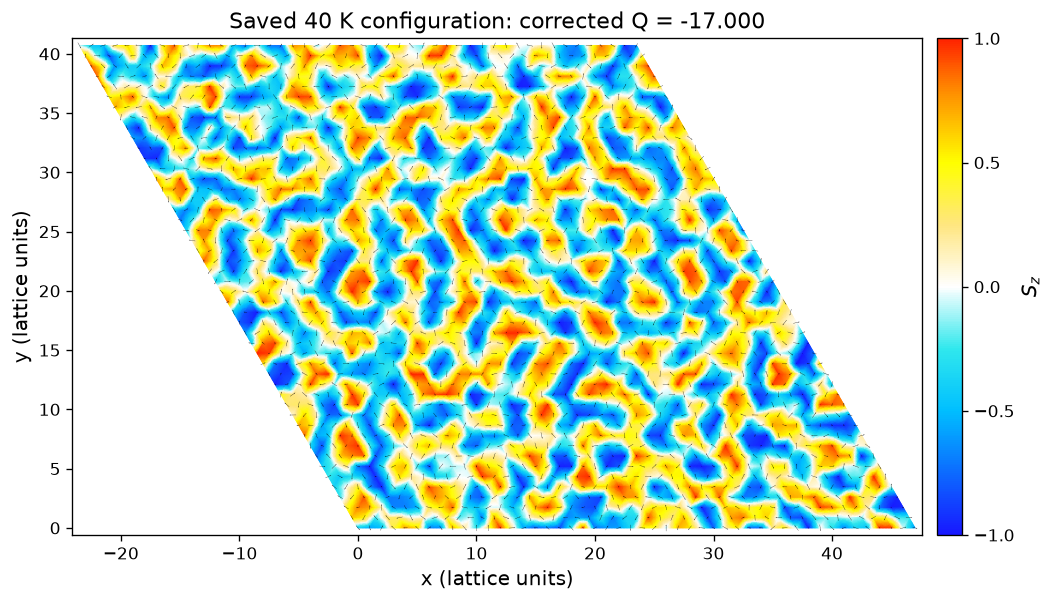

In [4]:
plot_spin_config(
    nix2_mc.spin_config, nix2_mc.lat,
    title=f"Saved 40 K configuration: corrected Q = {Q_initial:.3f}",
    figsize=(8, 7),
);

## 3. Temperature schedule and sampling
Default: cool from 40 K to 31 K. Set `TK_list = [40.0]` to sample only at 40 K. Q and chi retain the original magnetic-cell normalization; chi uses fluctuations of |Q|.


In [6]:
TK_list = np.arange(40.0, 20.0, -1.0)
num_eq_sweeps = source_parameters["num_eq_sweeps"]
num_meas_sweeps = source_parameters["num_meas_sweeps"]
converg_per_every = source_parameters["converg_per_every"]
meas_per_every = source_parameters["meas_per_every"]
obs = ["Q", "E", "chi", "Cv"]
save_plots = True


## 4. Save and run
Each execution resets to the loaded spins and the new seed, and writes to a fresh output folder. Original simulation files and Q samples are not modified or reused.


In [7]:
nix2_mc.set_proposal_angle(T_in_meV=TK_list[0] * KB_MEV_PER_K)
mc_parameters = {
    "Nx": nix2_lattice.Nx, "Ny": nix2_lattice.Ny, "Ns": nix2_lattice.Ns,
    "geometry": geometry, "model_params": model_params, "Nmuc": Nmuc,
    "seed": mc_seed, "source_seed": source_parameters["seed"],
    "source_file": source_file.resolve(), "initial_temperature_K": initial_temperature_K,
    "topological_charge_definition": "120-degree basis: (s00,s10,s11) and (s00,s11,s01)",
    "temperatures_K_list": TK_list, "observables": obs,
    "num_eq_sweeps": num_eq_sweeps, "num_meas_sweeps": num_meas_sweeps,
    "converg_per_every": converg_per_every, "meas_per_every": meas_per_every,
    "reset_probability": 0.02, "save_plots": save_plots,
}

current_folder = create_run_folder(
    root="nix2_simulation_results", parameters=mc_parameters,
    prefix="NiX2_topological_charge_corrected_from40K",
)

np.savez_compressed(current_folder / "initial_configuration.npz",
                    spins=initial_spins, coordinates=initial_point["coordinates"],
                    temperature_K=initial_temperature_K, corrected_Q=Q_initial)
print(current_folder)

results = run_mc_annealing(
    nix2_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps, num_meas_sweeps=num_meas_sweeps,
    converg_per_every=converg_per_every, meas_per_every=meas_per_every,
    observables=obs, Nmuc=Nmuc, save_plots=save_plots,
)


nix2_simulation_results\NiX2_topological_charge_corrected_from40K_20261103_111242_800245
T = 40.00 K, topological_charge = 14.810875, topological_charge_squared = 752.824625, energy = -27309.972863, chi = 0.048887, heat_capacity = 1.405194
T = 39.00 K, topological_charge = 7.4985, topological_charge_squared = 552.678, energy = -27572.157692, chi = 0.051214, heat_capacity = 1.337791
T = 38.00 K, topological_charge = 31.602875, topological_charge_squared = 1497.163375, energy = -27860.218599, chi = 0.090023, heat_capacity = 1.275878
T = 37.00 K, topological_charge = 1.51825, topological_charge_squared = 1040.64, energy = -28096.311785, chi = 0.084294, heat_capacity = 1.386019
T = 36.00 K, topological_charge = -14.17775, topological_charge_squared = 1686.256, energy = -28397.293937, chi = 0.099065, heat_capacity = 1.319284
T = 35.00 K, topological_charge = 10.955, topological_charge_squared = 2121.41475, energy = -28620.819918, chi = 0.112462, heat_capacity = 1.241012
T = 34.00 K, topolog

## 5. Plot Q and chi
The left axis shows |<Q>| divided by Nmuc squared, as in the original notebook; this is different from <|Q|>.


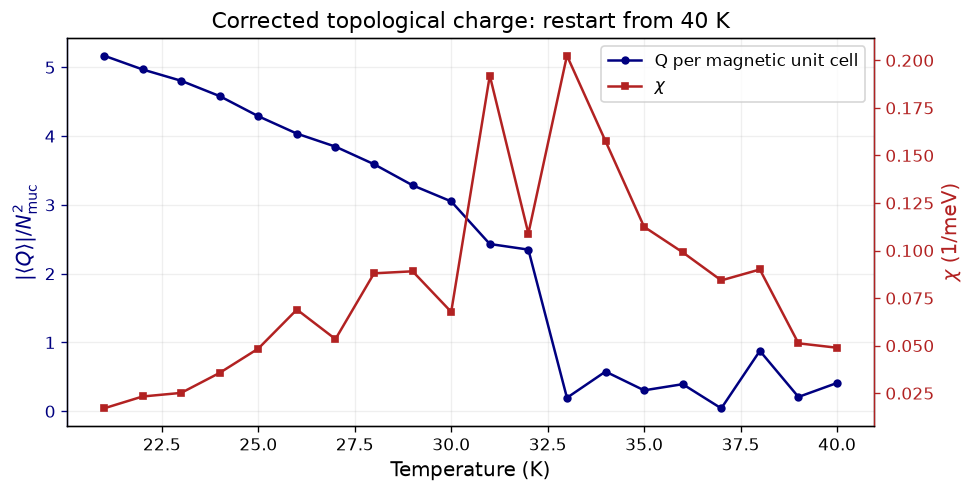

In [8]:
fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], np.abs(results["Q_data"]), results["chi_data"],
    xlabel="Temperature (K)",
    ylabel1=r"$|\langle Q\rangle|/N_{\mathrm{muc}}^2$", ylabel2=r"$\chi$ (1/meV)",
    label1="Q per magnetic unit cell", label2=r"$\chi$",
    title="Corrected topological charge: restart from 40 K",
    save_path=current_folder / "topological_charge_vs_temperature.png",
    flag_show=True,
)

In [ ]:
plot_spin_config(
    nix2_mc.spin_config, nix2_mc.lat,
    title=f"Final configuration: T = {TK_list[-1]:g} K",
    figsize=(8, 7), save_path=current_folder / "final_spin_configuration.png",
)
